# Notebook 1: Data and baseline for Kinyarwanda news topic classification

Task: assign a Kinyarwanda news article to one of 14 topics.
Dataset: KINNEWS (Niyongabo et al., 2020).

What this notebook does:
1. Loads the KINNEWS dataset
2. Explores class balance and text length
3. Cleans the text and makes a validation split
4. Runs four baseline experiments with classic machine learning
5. Evaluates the best one on the test set and saves everything to Google Drive

Run the cells from top to bottom. Each cell prints its result, so you can see what happened.

## 1. Setup

In [3]:
!pip install -q "datasets<4" scikit-learn pandas matplotlib joblib

In [4]:
import os, re, json, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)

# Save everything in Google Drive so it is still there if Colab disconnects
try:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/kinyarwanda_news_project1"
except ImportError:
    PROJECT_DIR = "./kinyarwanda_news_project1"

os.makedirs(PROJECT_DIR, exist_ok=True)
print("Project folder:", PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/kinyarwanda_news_project1


## 2. Load the dataset

I use the cleaned version of KINNEWS from the Hugging Face dataset `andreniyongabo/kinnews_kirnews`.
The loader tries three ways in order. If the first two fail, it looks for CSV files that you downloaded by hand from the authors' Google Drive link (see the README of the original GitHub repo) and uploaded to a folder called `kinnews_csv` inside your project folder.

In [5]:
LABEL_NAMES = ["politics", "sport", "economy", "health", "entertainment", "history",
               "technology", "tourism", "culture", "fashion", "religion",
               "environment", "education", "relationship"]


def to_frame(split):
    df = split.to_pandas() if hasattr(split, "to_pandas") else split
    return df[["label", "title", "content"]].copy()


def load_kinnews():
    from datasets import load_dataset
    name, config = "andreniyongabo/kinnews_kirnews", "kinnews_cleaned"

    # Way 1: the parquet copy that Hugging Face makes for script datasets
    try:
        ds = load_dataset(name, config, revision="refs/convert/parquet")
        print("Loaded from the parquet copy")
        return to_frame(ds["train"]), to_frame(ds["test"])
    except Exception as e:
        print("Way 1 failed:", type(e).__name__, str(e)[:150])

    # Way 2: the dataset loading script
    try:
        ds = load_dataset(name, config, trust_remote_code=True)
        print("Loaded with the dataset script")
        return to_frame(ds["train"]), to_frame(ds["test"])
    except Exception as e:
        print("Way 2 failed:", type(e).__name__, str(e)[:150])

    # Way 3: CSV files placed in the project folder by hand
    csv_dir = os.path.join(PROJECT_DIR, "kinnews_csv")
    files = glob.glob(os.path.join(csv_dir, "**", "*.csv"), recursive=True)
    train_files = [f for f in files if "train" in os.path.basename(f).lower()]
    test_files = [f for f in files if "test" in os.path.basename(f).lower()]
    if train_files and test_files:
        tr, te = pd.read_csv(train_files[0]), pd.read_csv(test_files[0])
        for d in (tr, te):
            if d["label"].min() == 1:
                d["label"] = d["label"] - 1
        print("Loaded from CSV files:", train_files[0], test_files[0])
        return tr[["label", "title", "content"]], te[["label", "title", "content"]]

    raise RuntimeError("Could not load the data. Put the KINNEWS cleaned train and "
                       "test CSV files in " + csv_dir + " and run this cell again.")


train_df, test_df = load_kinnews()
print("Train rows:", len(train_df), " Test rows:", len(test_df))
train_df.head(3)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Way 1 failed: ValueError BuilderConfig 'kinnews_cleaned' not found. Available: ['default']


README.md:   0%|          | 0.00/7.95k [00:00<?, ?B/s]

kinnews_kirnews.py:   0%|          | 0.00/5.37k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17014 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4254 [00:00<?, ? examples/s]

Loaded with the dataset script
Train rows: 17014  Test rows: 4254


,label,title,content
0,2,bugesera nyuma y’inzara yaharanzwe karahahira ...,mu myaka yashize cyane cyane umwaka w’ akarere...
1,4,mutzig beer fest itegerejwe n’abantu benshi ki...,mutzig beer fest thedition izabera juru parki ...
2,1,abakinnyi bamagare batanu berekeje isiganwa ny...,abakinnyi batanu berekeje asmara adrien niyons...


## 3. Look at the data

Before any modelling I check the class balance, empty rows, duplicates, and article length. These numbers go into the dataset section of the report.

In [6]:
for d in (train_df, test_df):
    d["label"] = d["label"].astype(int)
    d["title"] = d["title"].fillna("").astype(str)
    d["content"] = d["content"].fillna("").astype(str)
    d["label_name"] = d["label"].map(lambda i: LABEL_NAMES[i])

print("Empty content in train:", (train_df["content"].str.strip() == "").sum())
print("Empty content in test:", (test_df["content"].str.strip() == "").sum())
print("Duplicate articles in train:", train_df.duplicated(subset=["title", "content"]).sum())

# Articles that appear in both train and test would inflate the test score
overlap = set(zip(train_df["title"], train_df["content"])) & set(zip(test_df["title"], test_df["content"]))
print("Articles found in both train and test:", len(overlap))

counts = pd.DataFrame({
    "train": train_df["label_name"].value_counts(),
    "test": test_df["label_name"].value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False)
counts["train_share_%"] = (counts["train"] / counts["train"].sum() * 100).round(1)
counts

Empty content in train: 0
Empty content in test: 0
Duplicate articles in train: 7939
Articles found in both train and test: 678


,train,test,train_share_%
label_name,,,
politics,3929,979,23.1
economy,3519,899,20.7
entertainment,2578,651,15.2
sport,2469,635,14.5
health,1548,366,9.1
relationship,667,133,3.9
religion,628,154,3.7
technology,352,87,2.1
culture,341,95,2.0


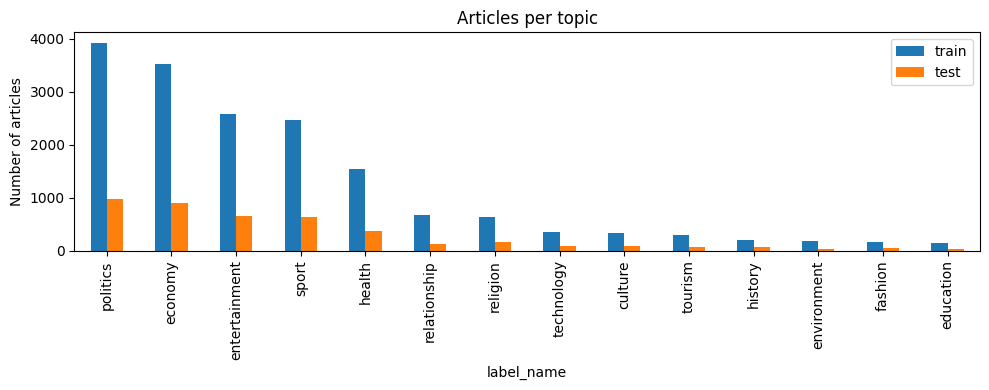

count    17014.0
mean       224.5
std        199.2
min          1.0
25%        133.0
50%        183.0
75%        259.0
max       8588.0
Name: n_words, dtype: float64
Articles longer than 256 words: 25.6 %
Articles longer than 512 words: 4.3 %


In [7]:
ax = counts[["train", "test"]].plot(kind="bar", figsize=(10, 4))
ax.set_title("Articles per topic")
ax.set_ylabel("Number of articles")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "class_distribution.png"), dpi=150)
plt.show()

train_df["n_words"] = train_df["content"].str.split().str.len()
print(train_df["n_words"].describe().round(1))
print("Articles longer than 256 words:", round((train_df["n_words"] > 256).mean() * 100, 1), "%")
print("Articles longer than 512 words:", round((train_df["n_words"] > 512).mean() * 100, 1), "%")

## 4. Clean the text, remove duplicates, and make a validation split

Cleaning is light on purpose: lowercase, remove web links, remove punctuation except the apostrophe (Kinyarwanda uses it in words like n'u), and collapse spaces.
I join the title and the content into one text.

The check in section 3 showed a real data quality problem: many articles appear more than once in the training set, and some articles appear in both the training and the test set. If I leave them in, the model can score well just by remembering articles it has already seen, and the test score is too optimistic. So I do three things:
1. Remove texts that appear with more than one label (they are contradictory).
2. Remove exact duplicate texts inside train and inside test.
3. Remove test articles that also appear in train.

Only after this do I make the validation split, which is 10 percent of the cleaned training data, split so that every topic keeps its share. The test set stays untouched until the very end.

In [8]:
URL = re.compile(r"https?://\S+|www\.\S+")
NOT_WORD = re.compile(r"[^\w\s']")
SPACES = re.compile(r"\s+")


def clean_text(text):
    text = text.lower()
    text = URL.sub(" ", text)
    text = NOT_WORD.sub(" ", text)
    return SPACES.sub(" ", text).strip()


for d in (train_df, test_df):
    d["text"] = (d["title"] + " . " + d["content"]).map(clean_text)

print(train_df["text"].iloc[0][:300])


def dedupe(df, name):
    n_before = len(df)
    labels_per_text = df.groupby("text")["label"].nunique()
    conflict = set(labels_per_text[labels_per_text > 1].index)
    df = df[~df["text"].isin(conflict)]
    df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
    print(name, "- rows before:", n_before, " texts with conflicting labels:", len(conflict),
          " rows after removing duplicates:", len(df))
    return df


raw_train_size, raw_test_size = len(train_df), len(test_df)
train_df = dedupe(train_df, "train")
test_df = dedupe(test_df, "test")

leak = test_df["text"].isin(set(train_df["text"]))
print("Test articles that also appear in train:", int(leak.sum()), "(removed from test)")
test_df = test_df[~leak].reset_index(drop=True)
print("Final sizes. Train:", len(train_df), " Test:", len(test_df))

clean_counts = pd.DataFrame({
    "train": train_df["label_name"].value_counts(),
    "test": test_df["label_name"].value_counts(),
}).fillna(0).astype(int).sort_values("train", ascending=False)
clean_counts["train_share_%"] = (clean_counts["train"] / clean_counts["train"].sum() * 100).round(1)
clean_counts.to_csv(os.path.join(PROJECT_DIR, "class_counts_after_cleaning.csv"))
print(clean_counts)

tr_df, val_df = train_test_split(train_df, test_size=0.10, stratify=train_df["label"],
                                 random_state=SEED)
print("Train:", len(tr_df), " Validation:", len(val_df), " Test:", len(test_df))

# Save the splits so notebook 2 uses exactly the same data
tr_df[["label", "label_name", "text"]].to_csv(os.path.join(PROJECT_DIR, "train.csv"), index=False)
val_df[["label", "label_name", "text"]].to_csv(os.path.join(PROJECT_DIR, "val.csv"), index=False)
test_df[["label", "label_name", "text"]].to_csv(os.path.join(PROJECT_DIR, "test.csv"), index=False)

bugesera nyuma y inzara yaharanzwe karahahira utundi turere mu myaka yashize cyane cyane umwaka w akarere bugesera kagaragayemo ikibazo cy amapfa akabije hari abantu bicwaga n inzara abandi bagasuhukamuri gihe uhatembereye ushobora kugira amateka cyangwa se amakabyankuru y abantu abenshi baturage ha
train - rows before: 17014  texts with conflicting labels: 109  rows after removing duplicates: 8966
test - rows before: 4254  texts with conflicting labels: 13  rows after removing duplicates: 2673
Test articles that also appear in train: 646 (removed from test)
Final sizes. Train: 8966  Test: 2027
               train  test  train_share_%
label_name                               
politics        1705   409           19.0
entertainment   1430   355           15.9
sport           1420   311           15.8
health          1101   256           12.3
economy         1057   227           11.8
relationship     639   123            7.1
religion         570   131            6.4
technology       212

## 5. Baseline experiments

A baseline is a simple model that the later, bigger model has to beat. I use TF-IDF features with a linear classifier.
TF-IDF gives each word a weight that is high when the word is common in one article but rare across all articles.

I use macro F1 as the main score. Macro F1 gives every topic the same weight, so a small topic like education counts as much as politics. Accuracy alone would hide poor results on small topics.

Each experiment changes one thing compared with the one before it:

| Name | Features | Classifier | What changed |
|---|---|---|---|
| B1 | word unigrams | Logistic Regression | the baseline |
| B2 | word unigrams and bigrams | Logistic Regression | added word pairs |
| B3 | word unigrams and bigrams | Linear SVM | changed the classifier |
| B4 | character n-grams (3 to 5) | Linear SVM | changed the features to characters |
| B5 | character n-grams (3 to 5) | Linear SVM with balanced class weights | gave small topics more weight |

Character n-grams are worth testing because Kinyarwanda words carry many prefixes and endings, so pieces of words may help.

B5 is there because the topics are very unbalanced. Politics has about 25 times more training articles than education, so a plain model tends to ignore the small topics.

In [9]:
experiments = {
    "B1 word 1gram + LogReg": (
        TfidfVectorizer(ngram_range=(1, 1), min_df=2, sublinear_tf=True, max_features=200000),
        LogisticRegression(max_iter=1000, C=10)),
    "B2 word 1-2gram + LogReg": (
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=300000),
        LogisticRegression(max_iter=1000, C=10)),
    "B3 word 1-2gram + LinearSVM": (
        TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=300000),
        LinearSVC(C=1.0)),
    "B4 char 3-5gram + LinearSVM": (
        TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True,
                        max_features=300000),
        LinearSVC(C=1.0)),
    "B5 char 3-5gram + LinearSVM balanced": (
        TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True,
                        max_features=300000),
        LinearSVC(C=1.0, class_weight="balanced")),
}

rows, fitted = [], {}
for name, (vec, clf) in experiments.items():
    start = time.time()
    X_tr = vec.fit_transform(tr_df["text"])
    X_val = vec.transform(val_df["text"])
    clf.fit(X_tr, tr_df["label"])
    pred = clf.predict(X_val)
    p, r, f1, _ = precision_recall_fscore_support(val_df["label"], pred, average="macro",
                                                  zero_division=0)
    rows.append({"experiment": name,
                 "val_accuracy": round(accuracy_score(val_df["label"], pred), 4),
                 "val_macro_precision": round(p, 4),
                 "val_macro_recall": round(r, 4),
                 "val_macro_f1": round(f1, 4),
                 "features": X_tr.shape[1],
                 "seconds": round(time.time() - start)})
    fitted[name] = (vec, clf)
    print(rows[-1])

results = pd.DataFrame(rows)
results.to_csv(os.path.join(PROJECT_DIR, "baseline_results_validation.csv"), index=False)
results

{'experiment': 'B1 word 1gram + LogReg', 'val_accuracy': 0.7703, 'val_macro_precision': 0.7881, 'val_macro_recall': 0.6417, 'val_macro_f1': 0.6888, 'features': 66375, 'seconds': 47}
{'experiment': 'B2 word 1-2gram + LogReg', 'val_accuracy': 0.7781, 'val_macro_precision': 0.7994, 'val_macro_recall': 0.637, 'val_macro_f1': 0.6856, 'features': 274356, 'seconds': 119}
{'experiment': 'B3 word 1-2gram + LinearSVM', 'val_accuracy': 0.7949, 'val_macro_precision': 0.7881, 'val_macro_recall': 0.6671, 'val_macro_f1': 0.7065, 'features': 274356, 'seconds': 22}
{'experiment': 'B4 char 3-5gram + LinearSVM', 'val_accuracy': 0.7904, 'val_macro_precision': 0.7956, 'val_macro_recall': 0.6807, 'val_macro_f1': 0.7189, 'features': 106923, 'seconds': 69}
{'experiment': 'B5 char 3-5gram + LinearSVM balanced', 'val_accuracy': 0.7915, 'val_macro_precision': 0.7525, 'val_macro_recall': 0.722, 'val_macro_f1': 0.7324, 'features': 106923, 'seconds': 58}


,experiment,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,features,seconds
0,B1 word 1gram + LogReg,0.7703,0.7881,0.6417,0.6888,66375,47
1,B2 word 1-2gram + LogReg,0.7781,0.7994,0.6370,0.6856,274356,119
2,B3 word 1-2gram + LinearSVM,0.7949,0.7881,0.6671,0.7065,274356,22
3,B4 char 3-5gram + LinearSVM,0.7904,0.7956,0.6807,0.7189,106923,69
4,B5 char 3-5gram + LinearSVM balanced,0.7915,0.7525,0.7220,0.7324,106923,58


## 6. Test the best baseline once

I pick the experiment with the best validation macro F1 and score it on the test set one time. I do not tune anything after seeing the test score.

In [10]:
best_name = results.sort_values("val_macro_f1", ascending=False).iloc[0]["experiment"]
print("Best on validation:", best_name)
vec, clf = fitted[best_name]

test_pred = clf.predict(vec.transform(test_df["text"]))
acc = accuracy_score(test_df["label"], test_pred)
p, r, f1, _ = precision_recall_fscore_support(test_df["label"], test_pred, average="macro",
                                              zero_division=0)
print("Test accuracy:", round(acc, 4))
print("Test macro precision:", round(p, 4), " recall:", round(r, 4), " F1:", round(f1, 4))
print()
print(classification_report(test_df["label"], test_pred, target_names=LABEL_NAMES, digits=3,
                            zero_division=0))

Best on validation: B5 char 3-5gram + LinearSVM balanced
Test accuracy: 0.7982
Test macro precision: 0.7166  recall: 0.7381  F1: 0.7189

               precision    recall  f1-score   support

     politics      0.756     0.733     0.744       409
        sport      0.927     0.977     0.951       311
      economy      0.726     0.722     0.724       227
       health      0.725     0.711     0.718       256
entertainment      0.893     0.868     0.880       355
      history      0.649     0.444     0.527        54
   technology      0.711     0.659     0.684        41
      tourism      0.500     1.000     0.667         8
      culture      0.706     0.571     0.632        42
      fashion      0.750     0.750     0.750        20
     religion      0.864     0.924     0.893       131
  environment      0.412     0.438     0.424        16
    education      0.636     0.618     0.627        34
 relationship      0.779     0.919     0.843       123

     accuracy                       

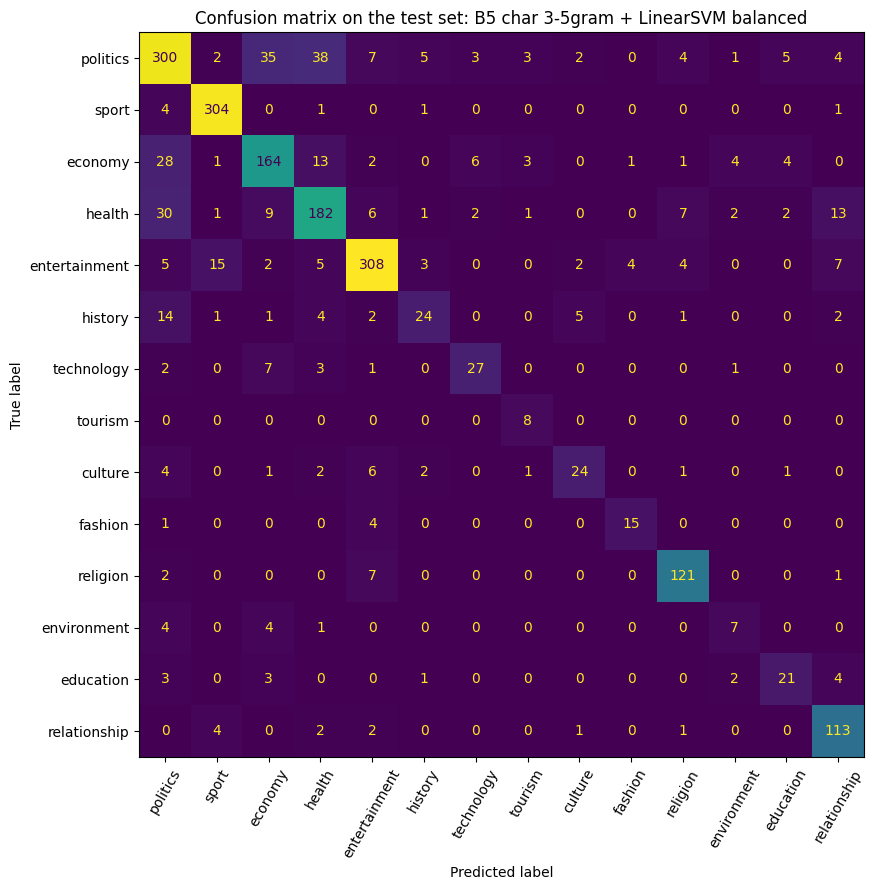

,confusion,count
0,politics predicted as health,38
1,politics predicted as economy,35
2,health predicted as politics,30
3,economy predicted as politics,28
4,entertainment predicted as sport,15
5,history predicted as politics,14
6,economy predicted as health,13
7,health predicted as relationship,13


In [11]:
cm = confusion_matrix(test_df["label"], test_pred, labels=range(len(LABEL_NAMES)))
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(ax=ax, xticks_rotation=60,
                                                           colorbar=False)
ax.set_title("Confusion matrix on the test set: " + best_name)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, "baseline_confusion_matrix.png"), dpi=150)
plt.show()

# Topics that get confused with each other most often
pairs = []
for i in range(len(LABEL_NAMES)):
    for j in range(len(LABEL_NAMES)):
        if i != j and cm[i, j] > 0:
            pairs.append((LABEL_NAMES[i] + " predicted as " + LABEL_NAMES[j], int(cm[i, j])))
pd.DataFrame(sorted(pairs, key=lambda x: -x[1])[:8], columns=["confusion", "count"])

## 7. Save everything

These files are used later for the model comparison, error analysis, and the report.

In [12]:
joblib.dump({"vectorizer": vec, "classifier": clf, "name": best_name},
            os.path.join(PROJECT_DIR, "best_baseline.joblib"))

errors = test_df[["label_name", "title", "content"]].copy()
errors["predicted"] = [LABEL_NAMES[i] for i in test_pred]
errors["correct"] = errors["label_name"] == errors["predicted"]
errors.to_csv(os.path.join(PROJECT_DIR, "baseline_test_predictions.csv"), index=False)

summary = {
    "best_baseline": best_name,
    "raw_train_size": int(raw_train_size), "raw_test_size": int(raw_test_size),
    "train_size": int(len(tr_df)), "val_size": int(len(val_df)), "test_size": int(len(test_df)),
    "test_accuracy": round(float(acc), 4),
    "test_macro_precision": round(float(p), 4),
    "test_macro_recall": round(float(r), 4),
    "test_macro_f1": round(float(f1), 4),
}
with open(os.path.join(PROJECT_DIR, "baseline_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))
print("Wrong predictions on the test set:", int((~errors["correct"]).sum()))

{
  "best_baseline": "B5 char 3-5gram + LinearSVM balanced",
  "raw_train_size": 17014,
  "raw_test_size": 4254,
  "train_size": 8069,
  "val_size": 897,
  "test_size": 2027,
  "test_accuracy": 0.7982,
  "test_macro_precision": 0.7166,
  "test_macro_recall": 0.7381,
  "test_macro_f1": 0.7189
}
Wrong predictions on the test set: 409


## Sources used in this notebook

Existing resources: the KINNEWS dataset (Niyongabo et al., 2020), the Hugging Face datasets library, scikit-learn, pandas, matplotlib, joblib.

My own work here: loading and checking the data, the cleaning function, the validation split, the four baseline experiments and their design, and the evaluation.